In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy 
from plotting_helper import *
%matplotlib inline

figures_path = 'figures/'
palette = plt.rcParams['axes.prop_cycle'].by_key()['color']  

In [45]:
def infinite_resources(parameters, state_var, dt ):
    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    txr_vec = state_var[3]     #terminating active complexes
    y_vec = state_var[2]   #protein concentrations

    new_x_vec = x_vec + dt * (-parameters['α'] * x_vec  + parameters['δ'] * txr_vec)
    new_xr_vec = xr_vec + dt * (parameters['α'] *  x_vec - parameters['β'] * xr_vec)
    new_txr_vec = txr_vec + dt * (-parameters['δ'] * txr_vec + parameters['β'] * xr_vec)
    new_y_vec = y_vec + dt * (parameters['δ'] * txr_vec - parameters['γ'] * y_vec)

    return new_x_vec, new_xr_vec, new_y_vec, new_txr_vec


def finite_ribosomes(parameters, state_var, dt ):
    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations
    txr_vec = state_var[3]     #terminating active complexes
    r = parameters['R'] - np.sum(xr_vec) - np.sum(txr_vec)  #concentration of free ribosomes

    new_x_vec = x_vec + dt * (-parameters['α']  * r * x_vec  + parameters['δ'] * txr_vec)
    new_xr_vec = xr_vec + dt * (parameters['α'] * r *  x_vec - parameters['β'] * xr_vec)
    new_txr_vec = txr_vec + dt * (-parameters['δ'] * txr_vec + parameters['β'] * xr_vec)
    new_y_vec = y_vec + dt * ( parameters['δ'] * txr_vec - parameters['γ'] * y_vec)

    return new_x_vec, new_xr_vec, new_y_vec, new_txr_vec

def finite_protein(parameters, state_var, dt ):

    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations
    txr_vec = state_var[3]     #terminating active complexes
    r = parameters['R'] - np.sum(xr_vec) - np.sum(txr_vec) #concentration of free ribosomes
    y_free = parameters['Y_max'] - np.sum(y_vec) 

    new_x_vec = x_vec + dt * (-parameters['α']  * r * x_vec  + parameters['δ'] * txr_vec)
    new_xr_vec = xr_vec + dt * (parameters['α'] * r *  x_vec - parameters['β'] * xr_vec* y_free)
    new_txr_vec = txr_vec + dt * (-parameters['δ'] * txr_vec + parameters['β'] * xr_vec * y_free)
    new_y_vec = y_vec + dt * ( parameters['δ'] * txr_vec - parameters['γ'] * y_vec)

    return new_x_vec, new_xr_vec, new_y_vec, new_txr_vec


def simulation_wrapper(state0, params, update, sim_time, dt, stop_crit = [100,1e-14]): 
    
    states = np.zeros([int(sim_time/dt)+1, state0.shape[0], state0.shape[1]])
    states[0] = state0
    stop_t = stop_crit[0]
    stop_min = stop_crit[1]
    stoped = False
    
    for t in range(int(sim_time/dt)): 
        states[t+1] = update(params, states[t], dt)
        if t > stop_t: 
            stoped = np.abs(np.mean(np.diff(states[t-stop_t:t]))) <=stop_min
        if stoped: 
            states = states[:t,:,:]
            break
        else: 
            if t == int(sim_time/dt)-1: 
                new_rec = np.zeros([int(sim_time/dt)*2, state0.shape[0], state0.shape[1]])
                new_rec[:int(sim_time/dt)+1] = states[:,:,:]
                sim_time += sim_time
                states = new_rec
        
    return states

In [3]:
#set parameters: 
rng = np.random.RandomState(seed = 5)
γ = 0.05
α = 0.1
δ = 0.5
x_init = 1
sim_time = 100 #should be enough
dt = 0.001
N = 2
l = np.array([1,10])
Y = N*2
Rs = np.linspace(0.01,10,20)
Ys = np.linspace(0.1, 5,10)

x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N]), np.zeros([N])]) 

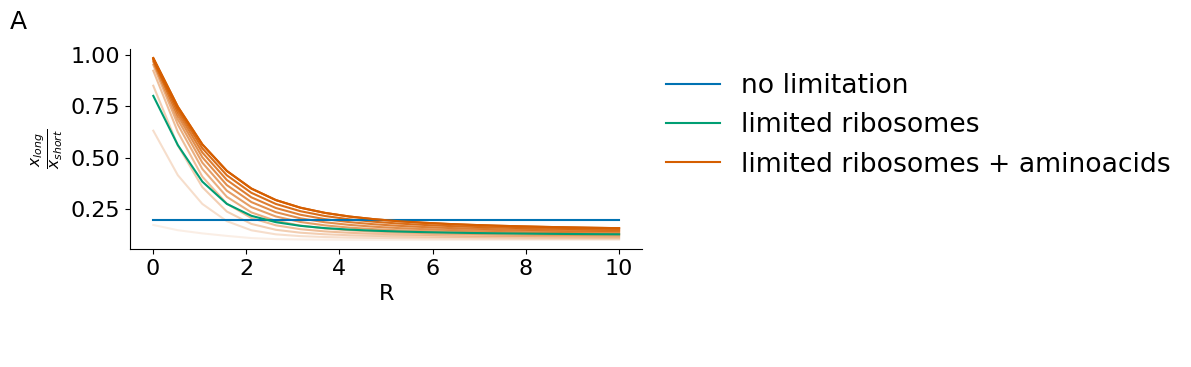

In [4]:
ys_bs = np.zeros([Rs.shape[0], N])
ys_lr = np.zeros([Rs.shape[0], N])
ys_lp = np.zeros([Rs.shape[0], Ys.shape[0], N])

parameters = dict()
parameters['α'] = α
parameters['β'] = α/l
parameters['γ'] = γ
parameters['δ'] = δ
parameters['l'] = l


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]

    res = simulation_wrapper(init_state,parameters,infinite_resources, sim_time, dt) 
    ys_bs[r,:]= res[-1,2,:]

    res = simulation_wrapper(init_state,parameters,finite_ribosomes, sim_time, dt) 
    ys_lr[r,:]= res[-1,2,:]
    
    for y in range(Ys.shape[0]):
        parameters['Y_max'] = Ys[y]
        res = simulation_wrapper(init_state,parameters,finite_protein, sim_time, dt) 
        ys_lp[r,y,:]= res[-1,2,:]

        
layout = '''
    AA
    AA
    '''



fig = plt.figure(figsize=(8, 4))

height_ratios = [1,0.1]
width_ratios = [1,0.1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'A':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='A', postfix='', offset_left=1.2)
for a in list('A'):
    axes[a].set_axis_off()


ax = fig.add_subplot(gs[0,0])
asr = np.linspace(0.1,1,Ys.shape[0])
for y in range(Ys.shape[0]):
    ax.plot(Rs, ys_lp[:,y,1]/ys_lp[:,y,0],color = palette[2], alpha = asr[y])
ax.plot(Rs, ys_bs[:,1]/ys_bs[:,0], label = 'no limitation', color = palette[0])
ax.plot(Rs, ys_lr[:,1]/ys_lr[:,0], label = 'limited ribosomes', color = palette[1])
ax.plot(Rs, ys_lp[:,y,1]/ys_lp[:,y,0], label = 'limited ribosomes + aminoacids', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
ax.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)

plt.show()


This simulation shows, that we can achieve the desired relationship as proposed in Seo et al. with and without a competition for aminoacids. However, there is a subtle difference between the models when looking at the change in absolute protein yield. The ribosome only model does not show the surpression of long protein translation, but rather a difference in the amount it increases. 

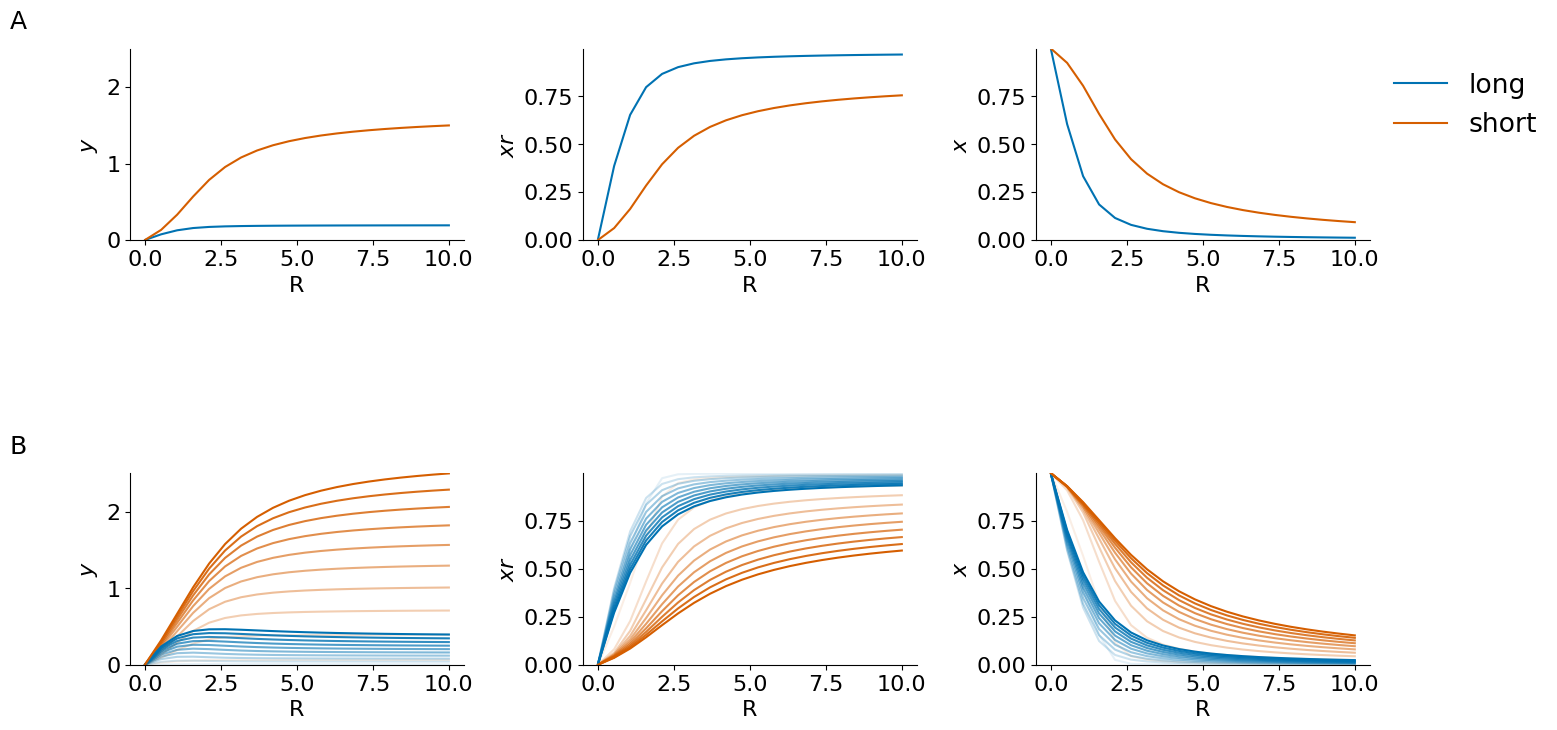

In [5]:
results_lr = np.zeros([Rs.shape[0], N,4])
results_lp = np.zeros([Rs.shape[0],Ys.shape[0], N,4])
 
#prepare parameter dictionary
parameters = dict()
parameters['α'] = α
parameters['β'] = α/l
parameters['γ'] = γ
parameters['l'] = l
parameters['δ'] = δ
parameters['Y_max'] = Y

for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]

    res = simulation_wrapper(init_state,parameters,finite_ribosomes, sim_time, dt) 
    results_lr[r]= res[-1].T
    
    for y in range(Ys.shape[0]):
        parameters['Y_max'] = Ys[y]
        res = simulation_wrapper(init_state,parameters,finite_protein, sim_time, dt) 
        results_lp[r,y]= res[-1].T

layout = '''
    AAAAA
    AAAAA
    BBBBB
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'AB':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='AB', postfix='', offset_left=1.2)
for a in list('AB'):
    axes[a].set_axis_off()


maxy = np.amax([np.amax(results_lp[:,:,:,2]),np.amax(results_lr[:,:,2])])
    
ax = fig.add_subplot(gs[0,0])
ax.plot(Rs, results_lr[:,1,2], label = 'long', color = palette[0])
ax.plot(Rs, results_lr[:,0,2], label = 'short', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$y$')
ax.set_ylim(0, maxy)
clear_axes(ax)

ax = fig.add_subplot(gs[2,0])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,2], label = 'long', color = palette[0], alpha = asr[y])
    ax.plot(Rs, results_lp[:,y,0,2], label = 'short', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$y$')
ax.set_ylim(0, maxy)
clear_axes(ax)

ax = fig.add_subplot(gs[0,2])
maxxr = np.amax([np.amax(results_lp[:,:,:,1]),np.amax(results_lr[:,:,1])])
ax.plot(Rs, results_lr[:,1,1], label = 'long', color = palette[0])
ax.plot(Rs, results_lr[:,0,1], label = 'short', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$xr$')
ax.set_ylim(0, maxxr)
clear_axes(ax)

ax = fig.add_subplot(gs[2,2])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,1], label = 'long', color = palette[0], alpha = asr[y])
    ax.plot(Rs, results_lp[:,y,0,1], label = 'short', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$xr$')
ax.set_ylim(0, maxxr)
clear_axes(ax)

ax = fig.add_subplot(gs[0,4])
maxx = np.amax([np.amax(results_lp[:,:,:,0]),np.amax(results_lr[:,:,0])])
ax.plot(Rs, results_lr[:,1,0], label = 'long', color = palette[0])
ax.plot(Rs, results_lr[:,0,0], label = 'short', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$x$')
ax.set_ylim(0, maxx)
ax.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)

ax = fig.add_subplot(gs[2,4])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,0], label = 'long', color = palette[0], alpha = asr[y])
    ax.plot(Rs, results_lp[:,y,0,0], label = 'short', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$x$')
ax.set_ylim(0, maxx)
clear_axes(ax)

plt.show()



This shows the competition in the total protein yeald. Interestingly, we dont see the similar competition in the actively translating complexes. However, this might be a limitation of the model as we push elongation and termination into the same step, rather than separate ones. 

A different model with an arbitrary termination step should be tested to see what is the buffering stage here. 

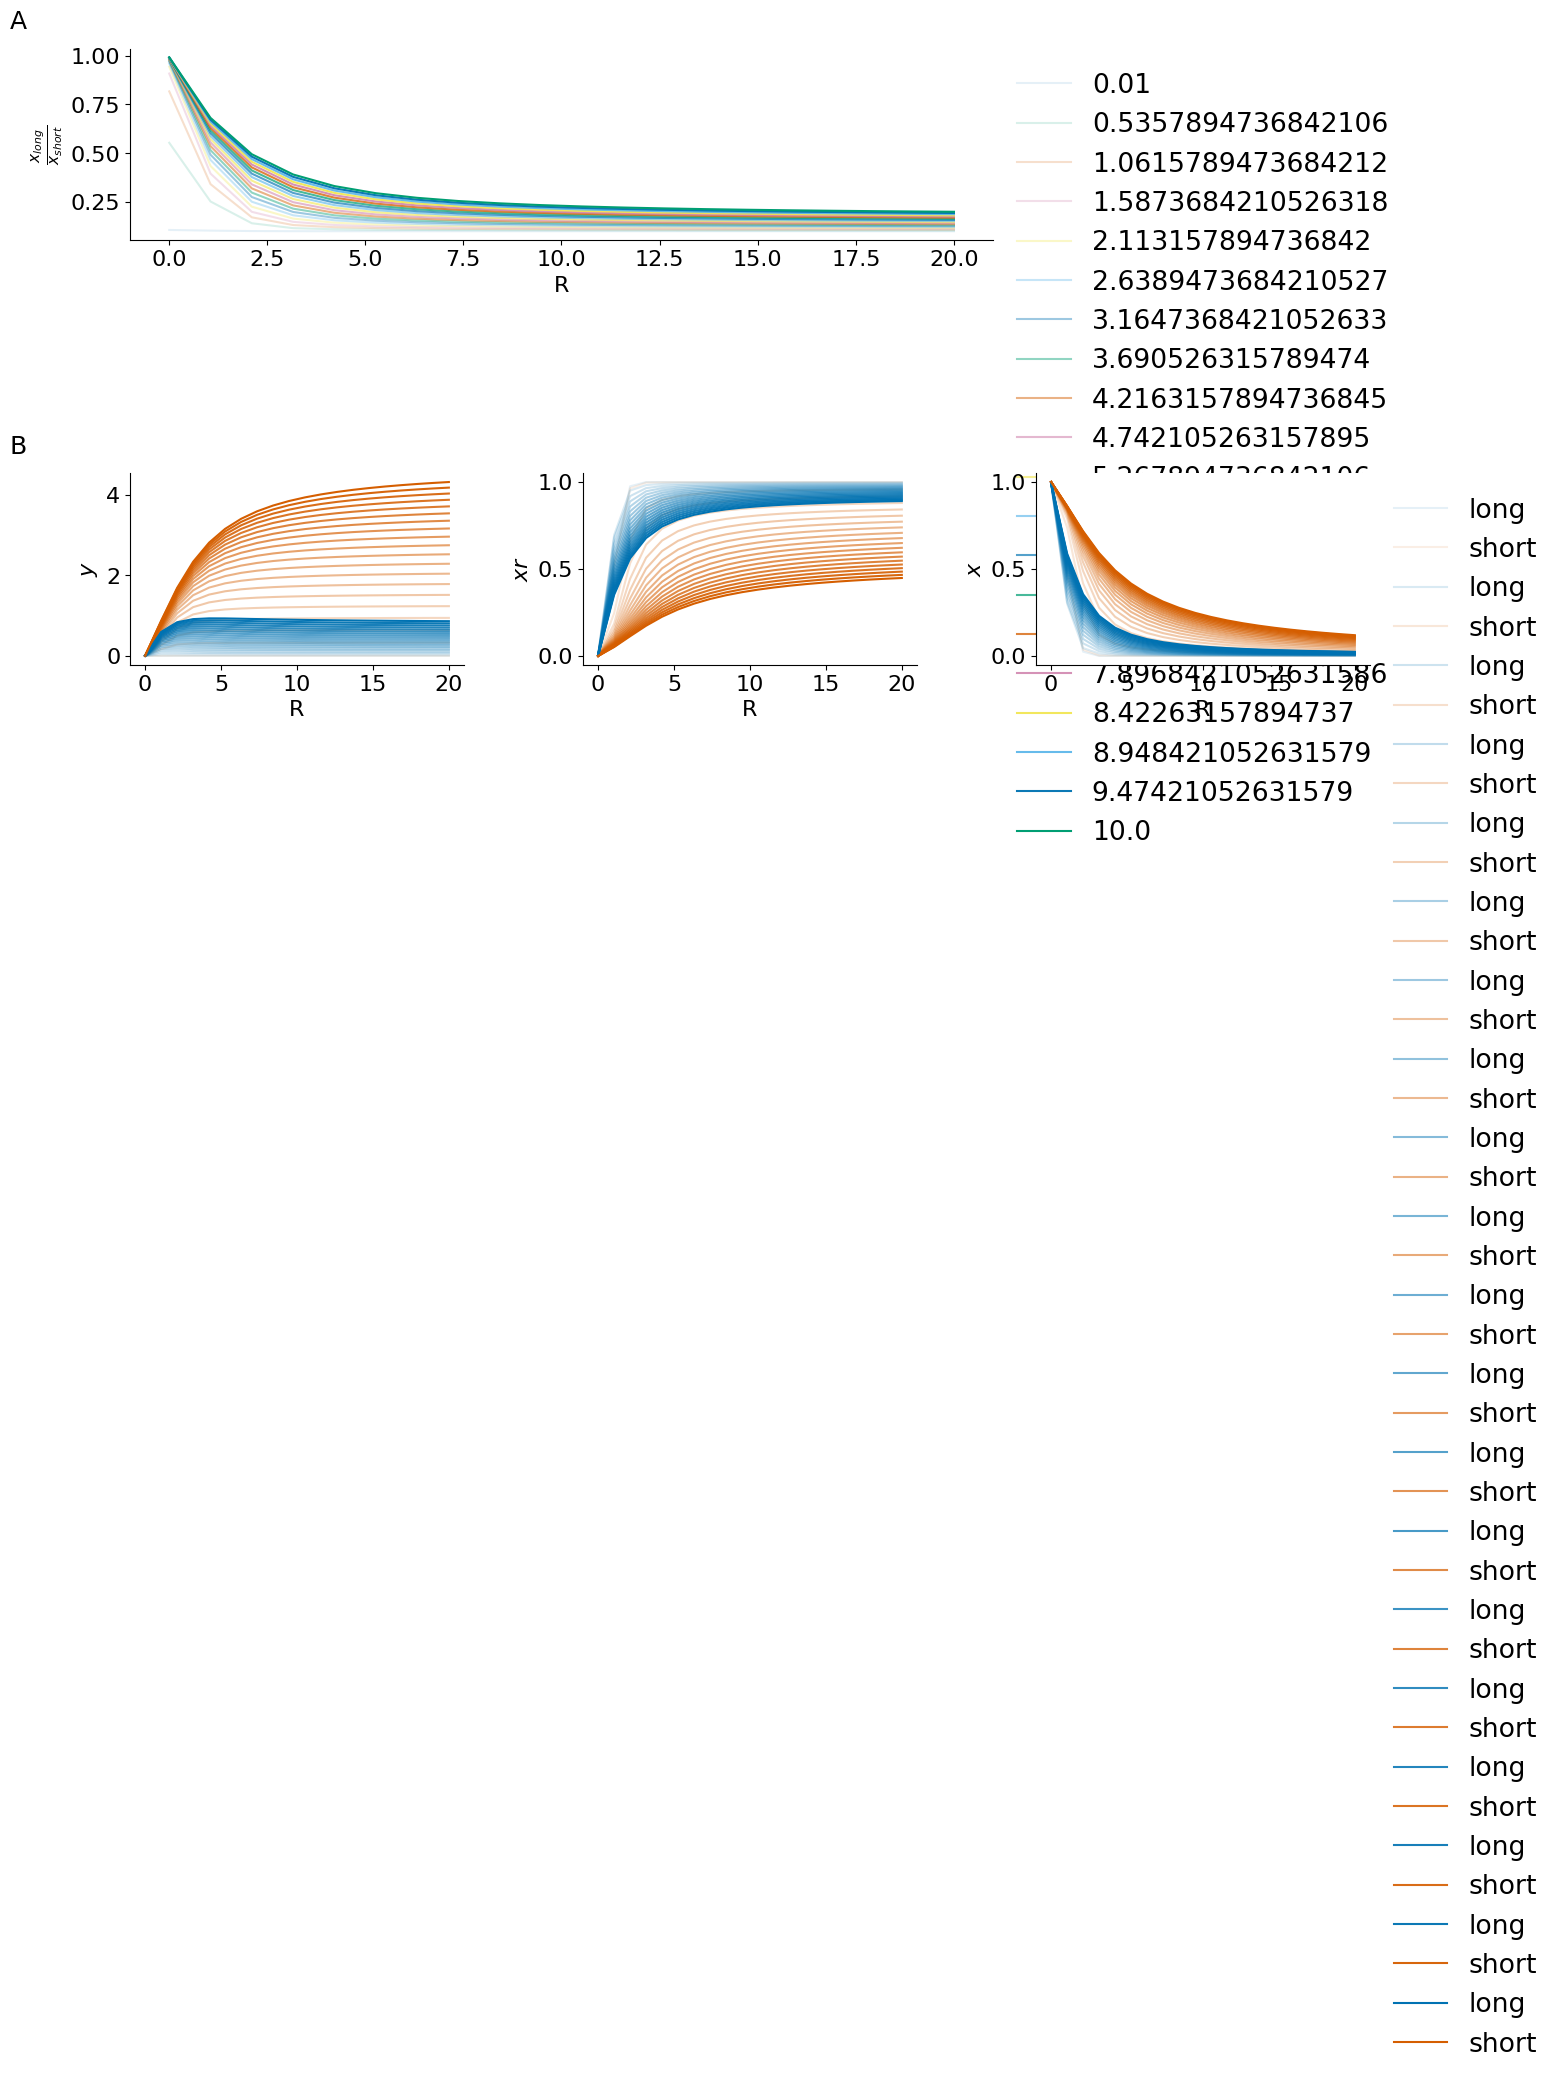

In [6]:
Rs = np.linspace(0.01,20,20)
Ys = np.linspace(0.01, 10,20)

results_lp = np.zeros([Rs.shape[0], Ys.shape[0], N,4])

parameters = dict()
parameters['α'] = α
parameters['β'] = α/l
parameters['γ'] = γ
parameters['l'] = l
parameters['δ'] = δ


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    
    for y in range(Ys.shape[0]):
        parameters['Y_max'] = Ys[y]
        res = simulation_wrapper(init_state,parameters,finite_protein, sim_time, dt) 
        results_lp[r,y]= res[-1].T


layout = '''
    AAAAA
    AAAAA
    BBBBB
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1,1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'AB':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='AB', postfix='', offset_left=1.2)
for a in list('AB'):
    axes[a].set_axis_off()

ax = fig.add_subplot(gs[0,0:4])
asr = np.linspace(0.1,1,Ys.shape[0])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,2]/results_lp[:,y,0,2], alpha = asr[y], label = Ys[y])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)



ax = fig.add_subplot(gs[2,0])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,2], label = 'long', color = palette[0], alpha = asr[y])
    ax.plot(Rs, results_lp[:,y,0,2], label = 'short', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$y$')
clear_axes(ax)

ax = fig.add_subplot(gs[2,2])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,1], label = 'long', color = palette[0], alpha = asr[y])
    ax.plot(Rs, results_lp[:,y,0,1], label = 'short', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$xr$')
clear_axes(ax)


ax = fig.add_subplot(gs[2,4])
for y in range(Ys.shape[0]):
    ax.plot(Rs, results_lp[:,y,1,0], label = 'long', color = palette[0], alpha = asr[y])
    ax.plot(Rs, results_lp[:,y,0,0], label = 'short', color = palette[2], alpha = asr[y])
ax.set_xlabel('R')
ax.set_ylabel('$x$')
ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)

plt.show()



Here we see that the protein resource has a start impact by increasing the competition for it. So we actually see the competition in the movement towards the saturated regime. 

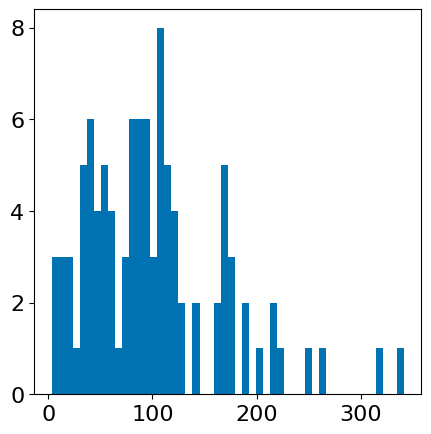

In [ ]:
#####sample lengths and show that this is not just a two species competition, but that the competition is increaed
#####when multiple species exists. 
N = 100
Y = N
Rs = np.linspace(0.01,200,num = 50)


results_lp = np.zeros([Rs.shape[0], N,4])
mean, std = 2, 50
l_sampels = rng.gamma(mean, std, N)

fig, ax = plt.subplots(1,1, figsize = (5,5))
ax.hist(l_sampels, bins = 50)
plt.show()
 
#prepare parameter dictionary
parameters = dict()
parameters['α'] = α
parameters['β'] = α/np.sort(l_sampels)
parameters['γ'] = γ
parameters['l'] = np.sort(l_sampels)
parameters['Y_max'] =  Y
parameters['δ'] = δ

#prepare the different groups for later analyses
s_1k = np.nonzero([parameters['l'] < 50])[1]
s_2k = np.delete(np.nonzero([parameters['l'] < 100])[1], s_1k)
s_3k = np.delete(np.delete(np.nonzero([parameters['l'] < 150])[1], s_2k), s_1k)
s_4k = np.delete(np.delete(np.delete(np.nonzero([parameters['l'] < 200])[1], s_3k), s_2k), s_1k)
b_4k = np.nonzero([parameters['l'] >= 200])[1]

x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N]), np.zeros([N])]) 


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    res = simulation_wrapper(init_state,parameters,finite_protein, sim_time, dt) 
    results_lp[r]= res[-1].T


layout = '''
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()


#normalising the amounts for easier plotting
normed_y = np.diff(results_lp[:,:,2].T, axis = 1) 
normed_xr = np.diff(results_lp[:,:,1].T, axis = 1)
normed_x = np.diff(results_lp[:,:,0].T , axis = 1)

maxy = 0.1 # np.amax(np.abs(normed_y))

    
ax = fig.add_subplot(gs[0,0])
hm = ax.imshow(normed_y, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Proteins')
fig.colorbar(hm, ax = ax )


ax = fig.add_subplot(gs[0,2])
hm = ax.imshow(normed_xr, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Translating mRNA')
fig.colorbar(hm, ax = ax )

ax = fig.add_subplot(gs[0,4])
hm = ax.imshow(normed_x, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
fig.colorbar(hm, ax = ax )
ax.set_title('Free mRNA')

plt.show()

layout = '''
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()
    
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']

for i in range(3): 
    ax = fig.add_subplot(gs[0,i*2])
    av1 = np.mean(results_lp[:,s_1k,2-i], axis = 1)
    av2 = np.mean(results_lp[:,s_2k,2-i], axis = 1)
    av3 = np.mean(results_lp[:,s_3k,2-i], axis = 1)
    av4 = np.mean(results_lp[:,s_4k,2-i], axis = 1)
    av5 = np.mean(results_lp[:,b_4k,2-i], axis = 1)
    
    ax.plot(Rs, av1, label = '<1k')
    ax.plot(Rs, av2, label = '1-2k')
    ax.plot(Rs, av3, label = '2-3k')
    ax.plot(Rs, av4, label = '3-4k')
    ax.plot(Rs, av5, label = '>4k')
    ax.set_xlabel('R')
    ax.set_ylabel(ylabels[i])
    if i == 2: 
        ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    clear_axes(ax)
    
plt.show()



We see this competition better in the differences between conditions when looking at a whole population of proteins. We should look at these plots for multiple aminoacid levels. 

**Low Aminoacid environment**

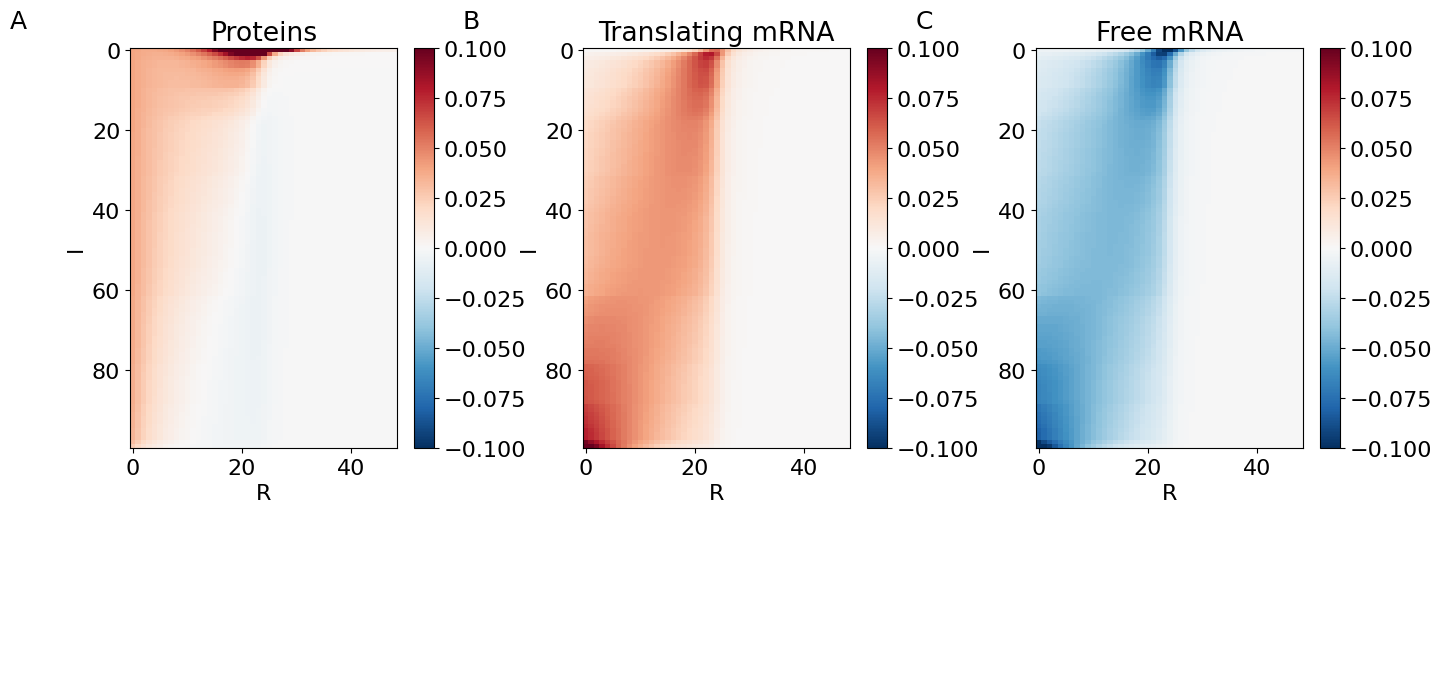

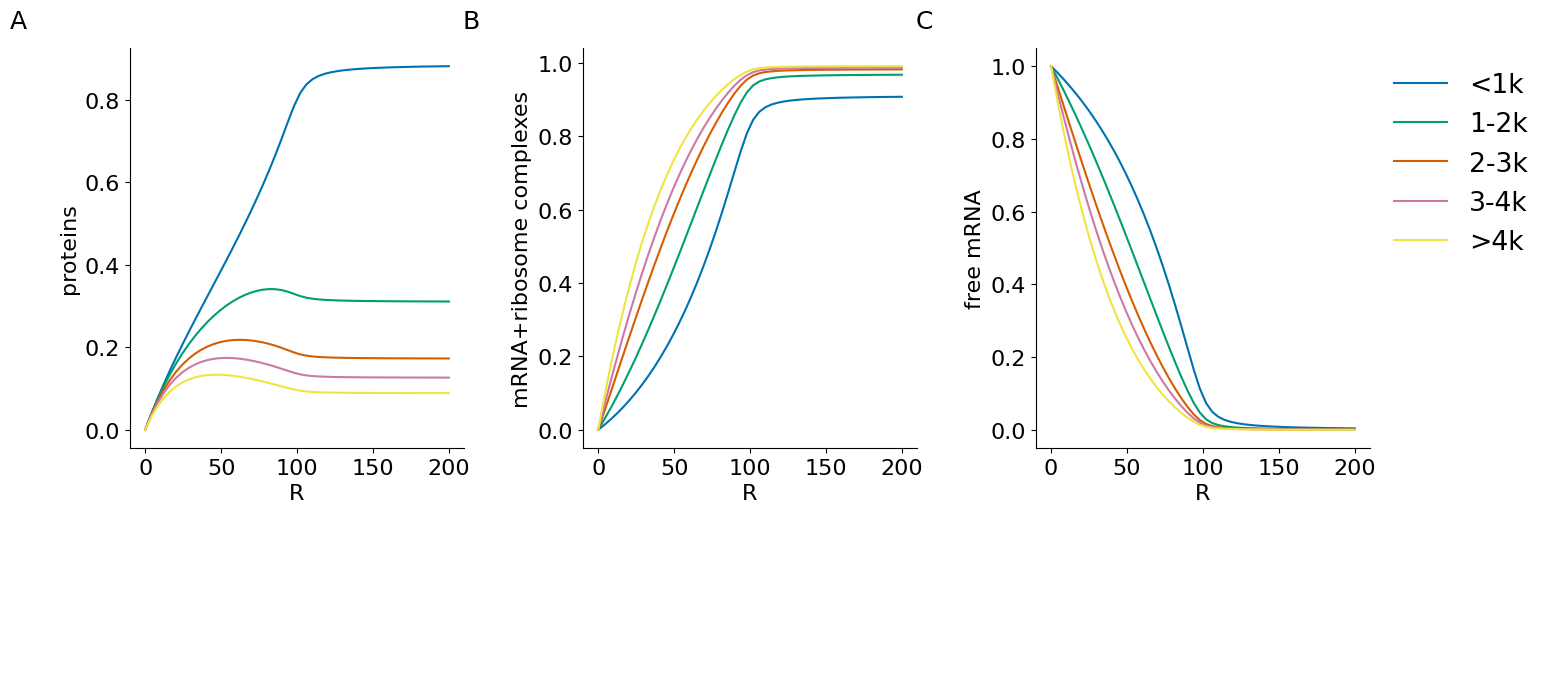

In [9]:
#####sample lengths and show that this is not just a two species competition, but that the competition is increaed
#####when multiple species exists. 
N = 100
Y = N/2
Rs = np.linspace(0.01,200,num = 50)


results_lp = np.zeros([Rs.shape[0], N,4])
 
#prepare parameter dictionary
parameters = dict()
parameters['α'] = α
parameters['β'] = α/np.sort(l_sampels)
parameters['γ'] = γ
parameters['l'] = np.sort(l_sampels)
parameters['Y_max'] =  Y
parameters['δ'] = δ

x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N]),np.zeros([N]) ]) 


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    res = simulation_wrapper(init_state,parameters,finite_protein, sim_time, dt) 
    results_lp[r]= res[-1].T


layout = '''
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()


#normalising the amounts for easier plotting
normed_y = np.diff(results_lp[:,:,2].T, axis = 1) 
normed_xr = np.diff(results_lp[:,:,1].T, axis = 1)
normed_x = np.diff(results_lp[:,:,0].T , axis = 1)

maxy = 0.1 # np.amax(np.abs(normed_y))

    
ax = fig.add_subplot(gs[0,0])
hm = ax.imshow(normed_y, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Proteins')
fig.colorbar(hm, ax = ax )


ax = fig.add_subplot(gs[0,2])
hm = ax.imshow(normed_xr, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Translating mRNA')
fig.colorbar(hm, ax = ax )

ax = fig.add_subplot(gs[0,4])
hm = ax.imshow(normed_x, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
fig.colorbar(hm, ax = ax )
ax.set_title('Free mRNA')

plt.show()

layout = '''
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()
    
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']

for i in range(3): 
    ax = fig.add_subplot(gs[0,i*2])
    av1 = np.mean(results_lp[:,s_1k,2-i], axis = 1)
    av2 = np.mean(results_lp[:,s_2k,2-i], axis = 1)
    av3 = np.mean(results_lp[:,s_3k,2-i], axis = 1)
    av4 = np.mean(results_lp[:,s_4k,2-i], axis = 1)
    av5 = np.mean(results_lp[:,b_4k,2-i], axis = 1)
    
    ax.plot(Rs, av1, label = '<1k')
    ax.plot(Rs, av2, label = '1-2k')
    ax.plot(Rs, av3, label = '2-3k')
    ax.plot(Rs, av4, label = '3-4k')
    ax.plot(Rs, av5, label = '>4k')
    ax.set_xlabel('R')
    ax.set_ylabel(ylabels[i])
    if i == 2: 
        ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    clear_axes(ax)
    
plt.show()


**High aminoacid environment**

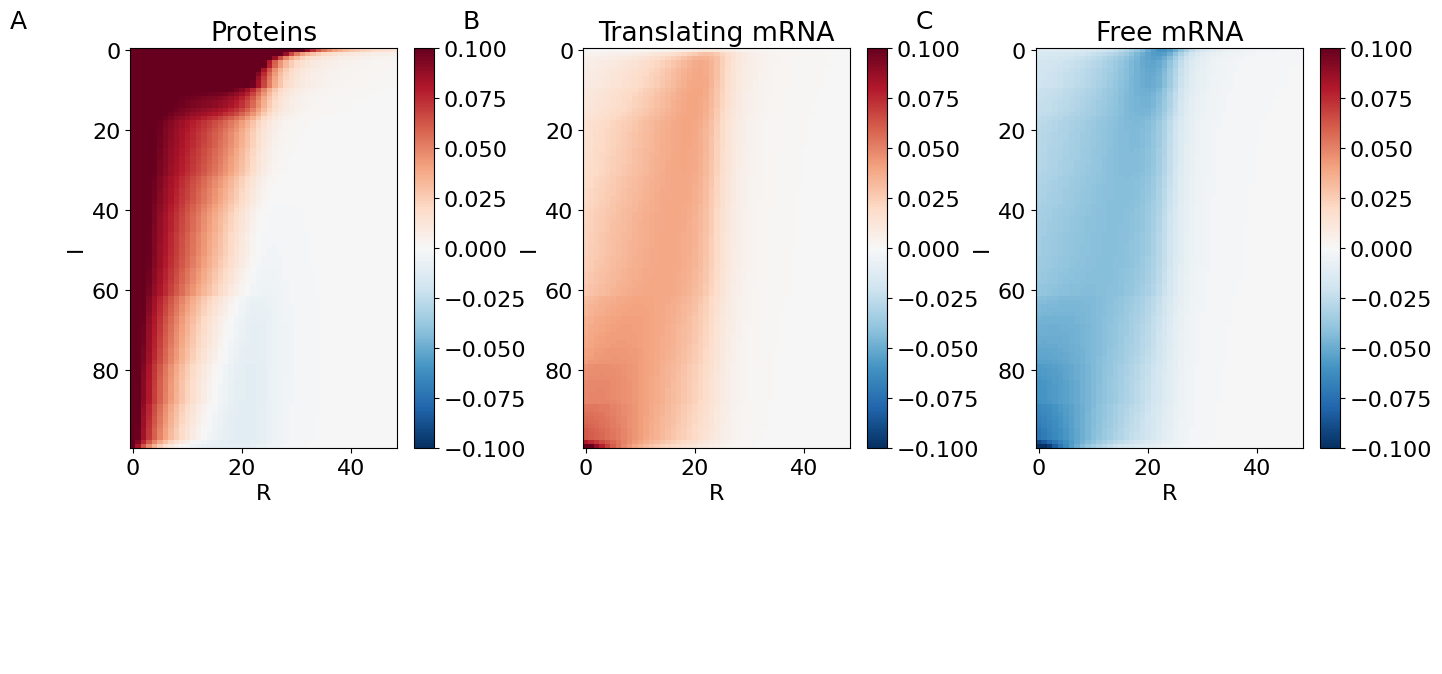

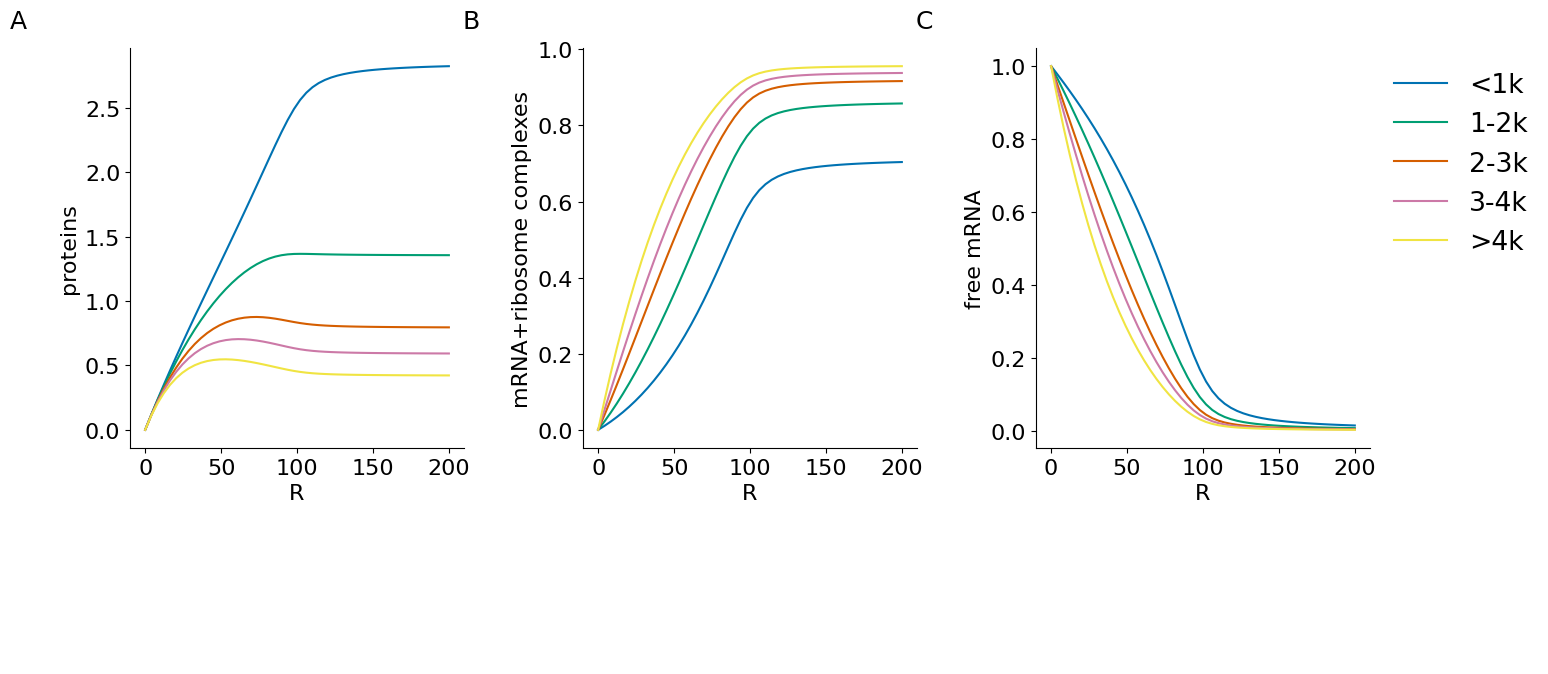

In [42]:
#####sample lengths and show that this is not just a two species competition, but that the competition is increaed
#####when multiple species exists. 
sim_time = 1000
N = 100
Y = N*2
Rs = np.linspace(0.01,200,num = 50)


results_lp = np.zeros([Rs.shape[0], N,4])
 
#prepare parameter dictionary
parameters = dict()
parameters['α'] = α
parameters['β'] = α/np.sort(l_sampels)
parameters['γ'] = γ
parameters['l'] = np.sort(l_sampels)
parameters['Y_max'] =  Y
parameters['δ'] = δ

x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N]),np.zeros([N])]) 


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    res = simulation_wrapper(init_state,parameters,finite_protein, sim_time, dt) 
    results_lp[r]= res[-1].T


layout = '''
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()


#normalising the amounts for easier plotting
normed_y = np.diff(results_lp[:,:,2].T, axis = 1) 
normed_xr = np.diff(results_lp[:,:,1].T, axis = 1)
normed_x = np.diff(results_lp[:,:,0].T , axis = 1)

maxy = 0.1 # np.amax(np.abs(normed_y))

    
ax = fig.add_subplot(gs[0,0])
hm = ax.imshow(normed_y, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Proteins')
fig.colorbar(hm, ax = ax )


ax = fig.add_subplot(gs[0,2])
hm = ax.imshow(normed_xr, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Translating mRNA')
fig.colorbar(hm, ax = ax )

ax = fig.add_subplot(gs[0,4])
hm = ax.imshow(normed_x, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
fig.colorbar(hm, ax = ax )
ax.set_title('Free mRNA')

plt.show()


layout = '''
    AABBC
    AABBC
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABC':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABC', postfix='', offset_left=1.2)
for a in list('ABC'):
    axes[a].set_axis_off()
    
ylabels = ['proteins', 'mRNA+ribosome complexes', 'free mRNA']

for i in range(3): 
    ax = fig.add_subplot(gs[0,i*2])
    av1 = np.mean(results_lp[:,s_1k,2-i], axis = 1)
    av2 = np.mean(results_lp[:,s_2k,2-i], axis = 1)
    av3 = np.mean(results_lp[:,s_3k,2-i], axis = 1)
    av4 = np.mean(results_lp[:,s_4k,2-i], axis = 1)
    av5 = np.mean(results_lp[:,b_4k,2-i], axis = 1)
    
    ax.plot(Rs, av1, label = '<1k')
    ax.plot(Rs, av2, label = '1-2k')
    ax.plot(Rs, av3, label = '2-3k')
    ax.plot(Rs, av4, label = '3-4k')
    ax.plot(Rs, av5, label = '>4k')
    ax.set_xlabel('R')
    ax.set_ylabel(ylabels[i])
    if i == 2: 
        ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    clear_axes(ax)
    
plt.show()


To compare this adequately with the Seo et al. data, we differentiate our species into 5 groups: <1k, 1-2k, 2-3k, 3-4k, >4k. This groups get progressively smaller. These are the second sets of plots above. 

Let's have a closer look t what happens with the trap stage, one example which shows the competition is enough. 

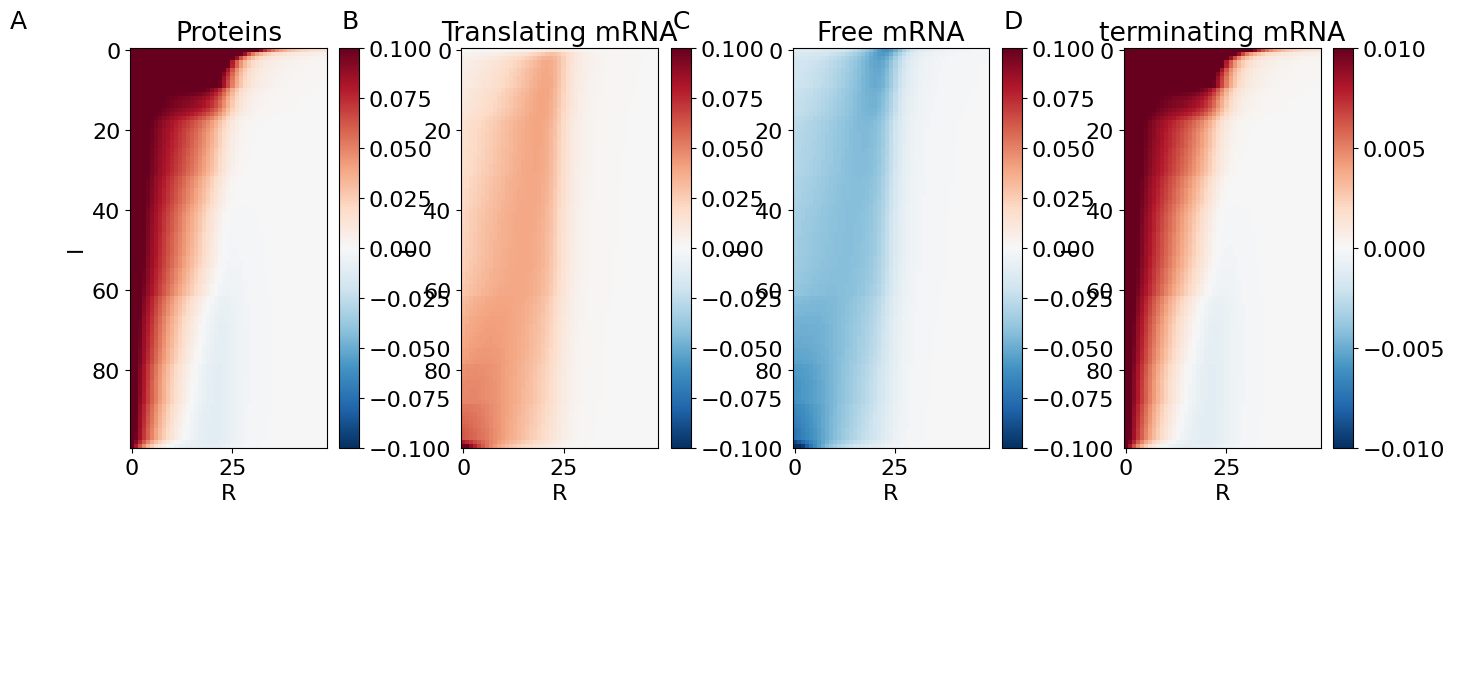

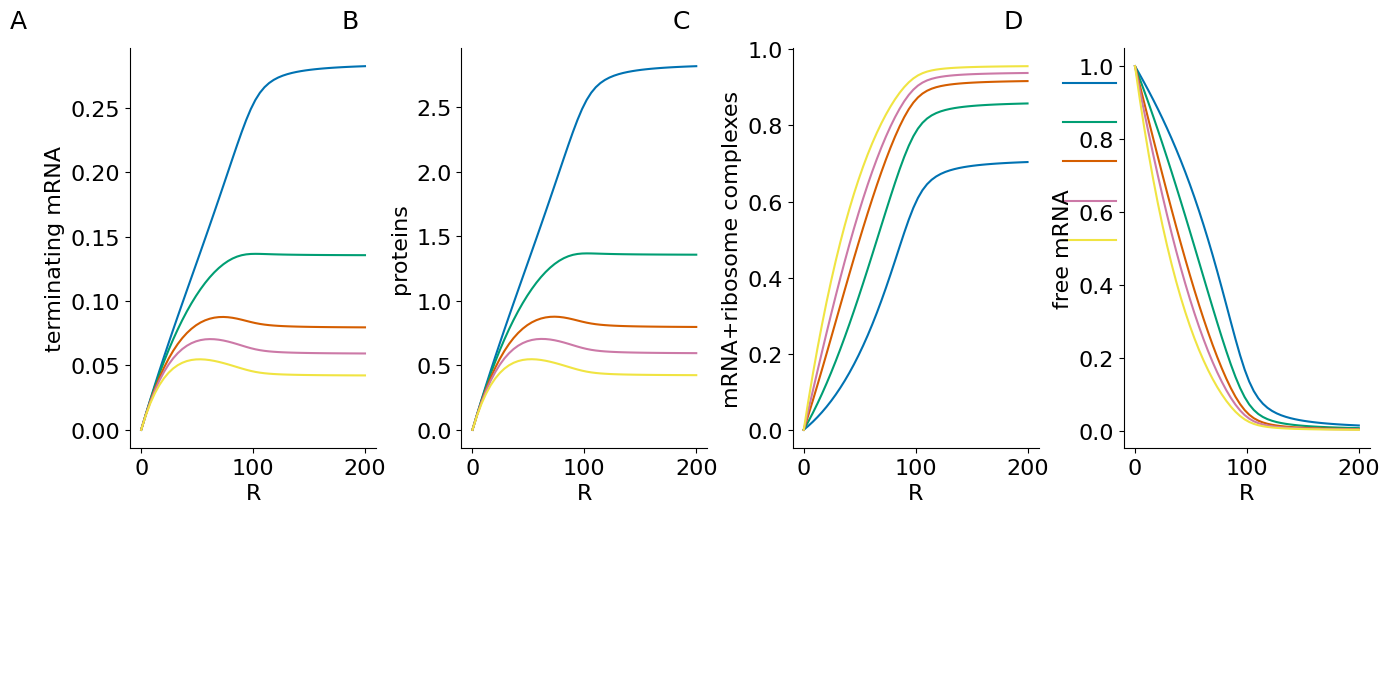

In [15]:
layout = '''
    AABBCCD
    AABBCCD
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABCD':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABCD', postfix='', offset_left=1.2)
for a in list('ABCD'):
    axes[a].set_axis_off()


#normalising the amounts for easier plotting
normed_y = np.diff(results_lp[:,:,2].T, axis = 1) 
normed_xr = np.diff(results_lp[:,:,1].T, axis = 1)
normed_x = np.diff(results_lp[:,:,0].T , axis = 1)

maxy = 0.1 # np.amax(np.abs(normed_y))

    
ax = fig.add_subplot(gs[0,0])
hm = ax.imshow(normed_y, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Proteins')
fig.colorbar(hm, ax = ax )


ax = fig.add_subplot(gs[0,2])
hm = ax.imshow(normed_xr, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
ax.set_title('Translating mRNA')
fig.colorbar(hm, ax = ax )

ax = fig.add_subplot(gs[0,4])
hm = ax.imshow(normed_x, cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy, vmax = maxy)
ax.set_xlabel('R')
ax.set_ylabel('l')
fig.colorbar(hm, ax = ax )
ax.set_title('Free mRNA')

ax = fig.add_subplot(gs[0,6])
hm = ax.imshow(np.diff(results_lp[:,:,3].T , axis = 1), cmap = 'RdBu_r', aspect = 'auto', vmin= -maxy*0.1, vmax = maxy*0.1)
ax.set_xlabel('R')
ax.set_ylabel('l')
fig.colorbar(hm, ax = ax )
ax.set_title('terminating mRNA')

plt.show()


layout = '''
    AABBCCD
    AABBCCD
    '''

fig = plt.figure(figsize=(16, 8))

height_ratios = [1,0.1]
width_ratios = [1,0.1,1,0.1,1,0.1,1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'ABCD':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='ABCD', postfix='', offset_left=1.2)
for a in list('ABCD'):
    axes[a].set_axis_off()
    
ylabels = ['terminating mRNA', 'proteins', 'mRNA+ribosome complexes', 'free mRNA']

for i in range(4): 
    ax = fig.add_subplot(gs[0,i*2])
    av1 = np.mean(results_lp[:,s_1k,3-i], axis = 1)
    av2 = np.mean(results_lp[:,s_2k,3-i], axis = 1)
    av3 = np.mean(results_lp[:,s_3k,3-i], axis = 1)
    av4 = np.mean(results_lp[:,s_4k,3-i], axis = 1)
    av5 = np.mean(results_lp[:,b_4k,3-i], axis = 1)
    
    ax.plot(Rs, av1, label = '<1k')
    ax.plot(Rs, av2, label = '1-2k')
    ax.plot(Rs, av3, label = '2-3k')
    ax.plot(Rs, av4, label = '3-4k')
    ax.plot(Rs, av5, label = '>4k')
    ax.set_xlabel('R')
    ax.set_ylabel(ylabels[i])
    if i == 2: 
        ax.legend(bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
    clear_axes(ax)
    
plt.show()


This model does not provides us with more inside. what we will do in the next step is to look at two example traces at specific ribosome concentrations and see if we can figure out why this is. 